# B02 — Productos de cobertura de tipos e inflación

**Objetivos:** comparar swap, cap ATM, cap OTM y collar de coste cero por coste esperado y riesgo; valorar los
productos con la curva de hoy; swaps de inflación cupón cero y deuda ligada a la inflación; caso de la utility.

**Fuentes:** Myint cap. 11 y 12; Hull cap. 29; Schofield & Bowler cap. 1 y 8. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves, discount, discount_t
from derivlab.dates import spot_date, add_months
from derivlab.scenarios import HullWhite
from derivlab.rate_options import cap_value, floor_value, caplets, zero_cost_floor_strike, implied_normal_vol
from derivlab.swaps import par_swap_rate
from derivlab.hedging import simulate_fixings, strategy_paths, strategy_table
from derivlab.inflation import (ZC_INFLATION_QUOTES, zc_rate, forward_index_ratio, forward_yoy, zc_swap_value,
                                real_rate_from_nominal, simulate_inflation)

m = sample_market()
estr, eur = build_curves(m)
ref, spot = m["ref_date"], spot_date(m["ref_date"])
hw = HullWhite(estr, eur, a=0.03, sigma=0.0085)

## 1. Precio de las cuatro coberturas a 5 años sobre 100 M€

Préstamo a Euribor 6M. Volatilidad normal de mercado: 85 pb plana (sin *smile*). El primer periodo ya está
fijado y no lleva opción. La prima se expresa también como coste anual: prima / (N · anualidad de la pata variable).

In [2]:
N, end5, VOL = 100e6, add_months(spot, 60), 0.0085
k_swap = par_swap_rate(ref, spot, end5, N, estr, eur)
cl = caplets(ref, estr, eur, spot, end5, N, k_swap, VOL)
float_annuity = sum(c["tau"] * c["df"] for c in cl)
cap_atm = cap_value(ref, estr, eur, spot, end5, N, k_swap, VOL)
cap_otm = cap_value(ref, estr, eur, spot, end5, N, k_swap + 0.005, VOL)
k_floor = zero_cost_floor_strike(ref, estr, eur, spot, end5, N, k_swap + 0.005, VOL)
running = {"atm": cap_atm / (N * float_annuity), "otm": cap_otm / (N * float_annuity)}
prices = pd.DataFrame([
    {"strategy": "1 swap", "strike": k_swap, "premium_eur": 0.0, "running_bp": 0.0},
    {"strategy": "2 ATM cap", "strike": k_swap, "premium_eur": cap_atm, "running_bp": running["atm"] * 1e4},
    {"strategy": "3 OTM cap (+50 bp)", "strike": k_swap + 0.005, "premium_eur": cap_otm, "running_bp": running["otm"] * 1e4},
    {"strategy": "4 zero-cost collar", "strike": k_swap + 0.005, "premium_eur": 0.0, "running_bp": 0.0},
])
print(prices.to_string(index=False, formatters={"strike": "{:.3%}".format, "premium_eur": "{:,.0f}".format,
                                                "running_bp": "{:.1f}".format}))
print(f"CASE 5y swap {k_swap:.3%}; ATM cap {cap_atm:,.0f} EUR ({running['atm'] * 1e4:.0f} bp/yr); "
      f"OTM cap {cap_otm:,.0f} EUR ({running['otm'] * 1e4:.0f} bp/yr); collar floor {k_floor:.3%}")

          strategy strike premium_eur running_bp
            1 swap 2.404%           0        0.0
         2 ATM cap 2.404%   2,205,193       51.4
3 OTM cap (+50 bp) 2.904%   1,365,255       31.8
4 zero-cost collar 2.904%           0        0.0
CASE 5y swap 2.404%; ATM cap 2,205,193 EUR (51 bp/yr); OTM cap 1,365,255 EUR (32 bp/yr); collar floor 1.946%


### ¿La volatilidad de mercado está cara frente al modelo de escenarios?

Las opciones se valoran a 85 pb. El modelo de escenarios implica una volatilidad algo menor en los caplets, así
que comprar opciones lleva una pequeña prima de volatilidad, como en la práctica (Myint incluye además el coste
de cubrir la vega y el *smile*).

In [3]:
times, fix_q = simulate_fixings(hw, 5, 40000, seed=21, tp_max=0.0)
model_vols = []
for c in cl[1::2]:
    k = int(round(c["t_fix"] / 0.5))
    k = min(max(k, 1), fix_q.shape[1] - 1)
    payoff = np.maximum(fix_q[:, k] - c["forward"], 0).mean()
    model_vols.append({"t_fix": round(c["t_fix"], 2), "model_normal_vol_bp": implied_normal_vol(payoff, c["forward"], c["forward"], c["t_fix"]) * 1e4})
print(pd.DataFrame(model_vols).round(1).to_string(index=False))

 t_fix  model_normal_vol_bp
   1.0                 83.3
   2.0                 83.3
   3.0                 83.3
   4.0                 83.5


## 2. Backtest por escenarios: coste esperado y riesgo de cada estrategia

Myint (cap. 11) compara las estrategias por la prima de cobertura realizada (frente a flotar) y por la
volatilidad unilateral frente al swap. Aquí se hace lo mismo sobre 40.000 escenarios a 5 años:
neutrales al riesgo y con la prima por plazo de B01 (mundo real).

In [4]:
_, fix_p = simulate_fixings(hw, 5, 40000, seed=21, tp_max=0.0060)
tables = {}
for name, f in [("risk_neutral", fix_q), ("real_world", fix_p)]:
    tab = strategy_table(strategy_paths(f, k_swap, k_swap + 0.005, running, k_floor))
    tables[name] = tab
    print(f"--- {name}")
    print(tab.to_string(formatters={c: "{:.3%}".format for c in ["expected_cost", "p95_cost", "worst_1pct",
                                     "hedge_premium", "one_sided_risk"]} | {"prob_beats_swap": "{:.0%}".format}))
rw = tables["real_world"]
print(f"CASE real world: expected cost floating {rw.loc['0 floating', 'expected_cost']:.3%}, swap {rw.loc['1 swap', 'expected_cost']:.3%}, "
      f"ATM cap {rw.loc['2 ATM cap', 'expected_cost']:.3%}, OTM cap {rw.loc['3 OTM cap', 'expected_cost']:.3%}, "
      f"collar {rw.loc['4 zero-cost collar', 'expected_cost']:.3%}")
print(f"CASE 1% worst case: floating {rw.loc['0 floating', 'worst_1pct']:.3%}, OTM cap {rw.loc['3 OTM cap', 'worst_1pct']:.3%}, "
      f"collar {rw.loc['4 zero-cost collar', 'worst_1pct']:.3%}")

--- risk_neutral
                   expected_cost p95_cost worst_1pct hedge_premium one_sided_risk prob_beats_swap
strategy                                                                                         
0 floating                2.393%   3.982%     4.632%        0.000%         0.672%             51%
1 swap                    2.404%   2.404%     2.404%        0.011%         0.000%              0%
2 ATM cap                 2.444%   2.882%     2.882%        0.051%         0.300%             33%
3 OTM cap                 2.428%   3.115%     3.136%        0.035%         0.387%             39%
4 zero-cost collar        2.367%   2.797%     2.818%       -0.026%         0.183%             52%
--- real_world
                   expected_cost p95_cost worst_1pct hedge_premium one_sided_risk prob_beats_swap
strategy                                                                                         
0 floating                2.110%   3.699%     4.349%        0.000%         0.524%     

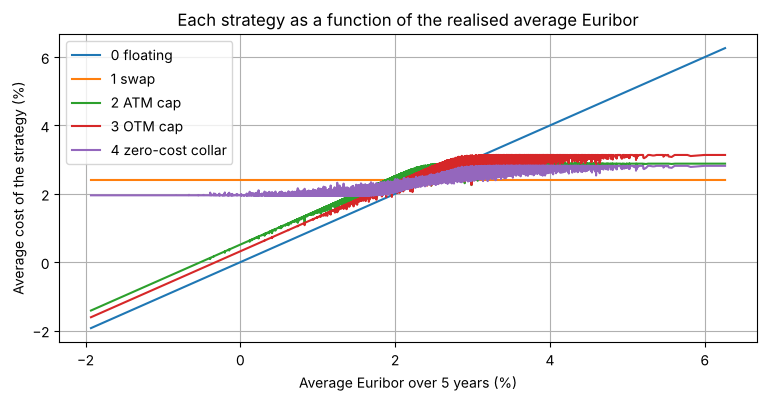

In [5]:
avg = {k: v.mean(axis=1) for k, v in strategy_paths(fix_p, k_swap, k_swap + 0.005, running, k_floor).items()}
order = np.argsort(avg["0 floating"])
for k, v in avg.items():
    plt.plot(avg["0 floating"][order] * 100, v[order] * 100, label=k)
plt.xlabel("Average Euribor over 5 years (%)"); plt.ylabel("Average cost of the strategy (%)")
plt.title("Each strategy as a function of the realised average Euribor"); plt.legend(); plt.show()

**Lectura.** En el mundo neutral al riesgo las cinco estrategias cuestan lo mismo en media, salvo la pequeña
prima de volatilidad de los caps: ningún producto es gratis. Lo que cambia es la forma del resultado: el swap fija,
el cap limita el máximo y conserva las bajadas, y el collar sustituye la prima por renunciar a las bajadas
por debajo del floor.

## 3. Inflación: swaps cupón cero y tipo real

Un swap de inflación cupón cero a *T* años intercambia $N[(1+K)^T - 1]$ por $N[I(T)/I(0) - 1]$ al vencimiento.
La curva de cotizaciones da el índice esperado y, por Fisher, el tipo real implícito.

In [6]:
infl = pd.DataFrame({"T": sorted(ZC_INFLATION_QUOTES)})
infl["zc_swap"] = [zc_rate(t) for t in infl["T"]]
infl["index_ratio"] = [forward_index_ratio(t) for t in infl["T"]]
infl["fwd_yoy"] = [forward_yoy(t) if t > 1 else zc_rate(1) for t in infl["T"]]
print(infl.to_string(index=False, formatters={"zc_swap": "{:.2%}".format, "index_ratio": "{:.4f}".format,
                                              "fwd_yoy": "{:.2%}".format}))
v = zc_swap_value(100e6, 0.0200, 10, discount_t(estr, 10.0))
print(f"CASE receiving inflation on 100M for 10y against 2.00% fixed is worth {v:,.0f} EUR today")

 T zc_swap index_ratio fwd_yoy
 1   1.95%      1.0195   1.95%
 2   1.98%      1.0400   2.01%
 3   2.00%      1.0612   2.04%
 5   2.03%      1.1057   2.09%
 7   2.07%      1.1542   2.19%
10   2.12%      1.2334   2.27%
15   2.18%      1.3819   2.35%
20   2.22%      1.5514   2.37%
30   2.25%      1.9494   2.34%
CASE receiving inflation on 100M for 10y against 2.00% fixed is worth 1,117,385 EUR today


## 4. Caso: una utility con ingresos ligados a la inflación refinancia 800 M€

**Aguas del Norte** (ficticia) tiene tarifas reguladas: el regulador le reconoce como coste de la deuda un
tipo real fijo del 1,70 % más la inflación realizada. Refinancia 800 M€ a 10 años con un diferencial de
crédito de 1,10 %. Tres alternativas y sus mezclas:

- **Fija nominal:** swap a 10 años + 1,10 %.
- **Ligada a la inflación:** cupón real de equilibrio más la inflación de cada año (coste económico, incluida la
  revalorización del principal).
- **Variable:** Euribor 6M + 1,10 %.

Riesgo: el **desfase** entre el coste real de la deuda y lo que reconoce el regulador, año a año.

In [7]:
SPREAD, R_REG, YEARS, NOTIONAL = 0.0110, 0.0170, 10, 800.0
nominal_fixed = par_swap_rate(ref, spot, add_months(spot, 120), 1.0, estr, eur) + SPREAD

# break-even real coupon: PV of the inflation-linked bond = PV of the nominal bond (€STR discounting)
ts = np.arange(1, YEARS + 1)
dfs = discount_t(estr, ts.astype(float))
pv_nominal = nominal_fixed * dfs.sum() + dfs[-1]
idx = np.array([forward_index_ratio(t) for t in ts])
real_coupon = (pv_nominal - idx[-1] * dfs[-1]) / (idx * dfs).sum()
print(f"CASE nominal fixed {nominal_fixed:.3%}; break-even real coupon {real_coupon:.3%} "
      f"(Fisher approximation {real_rate_from_nominal(nominal_fixed, zc_rate(10)):.3%})")

# joint scenarios: Euribor (Hull-White) and inflation correlated through the annual rate shocks
grid = np.arange(0.0, YEARS, 0.5)
x = hw.simulate(np.r_[grid, YEARS], 20000, seed=31)
fix = np.column_stack([hw.euribor_fixing(t, x[:, k]) for k, t in enumerate(grid)]) - 0.0060 * (1 - np.exp(-grid / 3))
annual_euribor = fix.reshape(fix.shape[0], YEARS, 2).mean(axis=2)
xa = x[:, ::2]
sd = hw.sigma * np.sqrt((1 - np.exp(-2 * hw.a)) / (2 * hw.a))
z_rates = (xa[:, 1:] - xa[:, :-1] * np.exp(-hw.a)) / sd
pi = simulate_inflation(YEARS, 20000, z_rates, rho=0.5, vol=0.010)

cost = {"fixed": np.full_like(pi, nominal_fixed), "linker": real_coupon + pi, "floating": annual_euribor + SPREAD}
allowed = R_REG + pi
rows = []
for w_fix, w_lnk, w_flt in [(1, 0, 0), (0, 1, 0), (0, 0, 1), (0.5, 0.5, 0), (0.5, 0.25, 0.25), (0.25, 0.5, 0.25)]:
    c = w_fix * cost["fixed"] + w_lnk * cost["linker"] + w_flt * cost["floating"]
    gap = c - allowed                       # positive = the utility pays more than the regulator allows
    avg_gap = gap.mean(axis=1)
    rows.append({"fixed": w_fix, "linker": w_lnk, "floating": w_flt, "mean_gap": avg_gap.mean(),
                 "p95_gap": np.quantile(avg_gap, 0.95), "annual_gap_vol": gap.std(axis=1).mean(),
                 "p95_gap_meur": np.quantile(avg_gap, 0.95) * NOTIONAL})
gaps = pd.DataFrame(rows)
print(gaps.to_string(index=False, formatters={"fixed": "{:.0%}".format, "linker": "{:.0%}".format,
                                              "floating": "{:.0%}".format, "mean_gap": "{:.3%}".format,
                                              "p95_gap": "{:.3%}".format, "annual_gap_vol": "{:.3%}".format,
                                              "p95_gap_meur": "{:.1f}".format}))
best_mix = gaps.sort_values("annual_gap_vol").iloc[0]
print(f"CASE gap volatility: all fixed {gaps.annual_gap_vol.iloc[0]:.2%}, all inflation-linked "
      f"{gaps.annual_gap_vol.iloc[1]:.2%}, all floating {gaps.annual_gap_vol.iloc[2]:.2%}")

CASE nominal fixed 3.785%; break-even real coupon 1.550% (Fisher approximation 1.630%)
fixed linker floating mean_gap p95_gap annual_gap_vol p95_gap_meur
 100%     0%       0%  -0.030%  0.823%         0.800%          6.6
   0%   100%       0%  -0.150% -0.150%         0.000%         -1.2
   0%     0%     100%  -0.370%  1.620%         1.157%         13.0
  50%    50%       0%  -0.090%  0.337%         0.400%          2.7
  50%    25%      25%  -0.145%  0.477%         0.618%          3.8
  25%    50%      25%  -0.175%  0.345%         0.439%          2.8
CASE gap volatility: all fixed 0.80%, all inflation-linked 0.00%, all floating 1.16%


**Lectura.** Con ingresos indexados, la deuda fija nominal no es la opción sin riesgo: el desfase con el
regulador se mueve con la inflación. La deuda ligada a la inflación elimina ese desfase. La variable lo compensa
solo en parte, porque Euribor e inflación están correlacionados de forma imperfecta. El precio de la
protección es el diferencial entre el cupón real de equilibrio y el tipo real que reconoce el regulador.

## 5. Comprobaciones

In [8]:
rn = tables["risk_neutral"]
assert abs(rn.loc["1 swap", "expected_cost"] - rn.loc["0 floating", "expected_cost"]) < 0.0005
assert rw.loc["4 zero-cost collar", "worst_1pct"] <= k_swap + 0.005 + 1e-12
assert rw.loc["3 OTM cap", "p95_cost"] < rw.loc["0 floating", "p95_cost"]
assert abs(floor_value(ref, estr, eur, spot, end5, N, k_floor, VOL) - cap_otm) < 1.0
assert gaps.annual_gap_vol.iloc[1] < 1e-12 and gaps.annual_gap_vol.iloc[1] < gaps.annual_gap_vol.iloc[0]
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuánto cuesta en euros un cap a 5 años al 3,50 % sobre 100 M€ con 85 pb de volatilidad?
2. **Intermedio.** Construye un collar de coste cero con el cap al 3,00 %. ¿Dónde queda el floor y cuál es el peor coste anual posible?
3. **Avanzado.** En el caso de la utility, ¿cuánto sube el desfase medio si el regulador reconoce un 1,50 % real en lugar de 1,70 %? ¿Cambia la mezcla óptima?

## Soluciones

In [9]:
c35 = cap_value(ref, estr, eur, spot, end5, N, 0.035, VOL)
print(f"Cap 3.50%: {c35:,.0f} EUR ({c35 / (N * float_annuity) * 1e4:.1f} bp per year)")

Cap 3.50%: 728,796 EUR (17.0 bp per year)


In [10]:
kf3 = zero_cost_floor_strike(ref, estr, eur, spot, end5, N, 0.030, VOL)
print(f"Zero-cost collar: cap 3.00%, floor {kf3:.3%}; worst all-in cost = 3.00% + margin")

Zero-cost collar: cap 3.00%, floor 1.864%; worst all-in cost = 3.00% + margin


In [11]:
gap_low = gaps.mean_gap + (R_REG - 0.0150)
print(pd.DataFrame({"mix": gaps[["fixed", "linker", "floating"]].astype(str).agg("/".join, axis=1),
                    "mean_gap_at_1.50%": gap_low}).to_string(index=False, formatters={"mean_gap_at_1.50%": "{:.3%}".format}))
print("The mean gap rises by 0.20% for every mix; the ranking by volatility does not change.")

          mix mean_gap_at_1.50%
  1.0/0.0/0.0            0.170%
  0.0/1.0/0.0            0.050%
  0.0/0.0/1.0           -0.170%
  0.5/0.5/0.0            0.110%
0.5/0.25/0.25            0.055%
0.25/0.5/0.25            0.025%
The mean gap rises by 0.20% for every mix; the ranking by volatility does not change.
